### Day 2: MFCC feature extraction


In [ ]:

BASE = r"C:\Users\Abdul Rehman\Documents\Projects\emotion-recognition"    

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
from tqdm import tqdm

BASE = Path(BASE)
(BASE / "features").mkdir(exist_ok=True)
print("Project folder exists:", BASE.exists())
print("RAVDESS folder exists:", (BASE / "data" / "ravdess").exists())

Project folder exists: True
RAVDESS folder exists: True


In [ ]:
# 2. Feature settings and functions 
SR = 22050          # every clip is resampled to this rate
DURATION = 3        # seconds of audio to keep
OFFSET = 0.5        # skip the first 0.5 s (usually silence)
N_MFCC = 40         # MFCC coefficients per frame
HOP_LENGTH = 512    # samples between frames
MAX_FRAMES = 130    # fixed number of frames per clip


def mfcc_from_signal(y, sr=SR):
    """Waveform -> MFCC matrix of fixed shape (N_MFCC, MAX_FRAMES)."""
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC, hop_length=HOP_LENGTH)
    if mfcc.shape[1] < MAX_FRAMES:                                   # short clip -> pad with zeros
        mfcc = np.pad(mfcc, ((0, 0), (0, MAX_FRAMES - mfcc.shape[1])))
    return mfcc[:, :MAX_FRAMES].astype(np.float32)                   # long clip -> crop


def extract_mfcc(path):
    """Audio file path -> MFCC matrix of shape (N_MFCC, MAX_FRAMES)."""
    y, _ = librosa.load(path, sr=SR, duration=DURATION, offset=OFFSET)
    return mfcc_from_signal(y)

In [ ]:
# 3. Load the metadata table from Day 1 
df = pd.read_csv(BASE / "data" / "metadata.csv")

lookup = {f.name: str(f) for f in (BASE / "data" / "ravdess").rglob("*.wav")}
df["path"] = df["path"].map(lambda p: lookup.get(Path(p).name))

print("Rows:", len(df))
print("Files not found:", df["path"].isna().sum())     
df.head()

Rows: 1440
Files not found: 0


,path,emotion,intensity,statement,repetition,actor,gender
0,C:\Users\Abdul Rehman\Documents\Projects\emoti...,angry,normal,1,1,1,male
1,C:\Users\Abdul Rehman\Documents\Projects\emoti...,angry,normal,1,2,1,male
2,C:\Users\Abdul Rehman\Documents\Projects\emoti...,angry,normal,2,1,1,male
3,C:\Users\Abdul Rehman\Documents\Projects\emoti...,angry,normal,2,2,1,male
4,C:\Users\Abdul Rehman\Documents\Projects\emoti...,angry,strong,1,1,1,male


In [ ]:
# 4. Test the extraction function on ONE clip
sample = df.iloc[0]
mfcc = extract_mfcc(sample["path"])
print(f"Emotion: {sample['emotion']} | actor {sample['actor']}")
print("MFCC shape:", mfcc.shape)                       # expected (40, 130)
print("dtype:", mfcc.dtype, "| min:", mfcc.min().round(1), "| max:", mfcc.max().round(1))

Emotion: angry | actor 1
MFCC shape: (40, 130)
dtype: float32 | min: -723.4 | max: 180.6


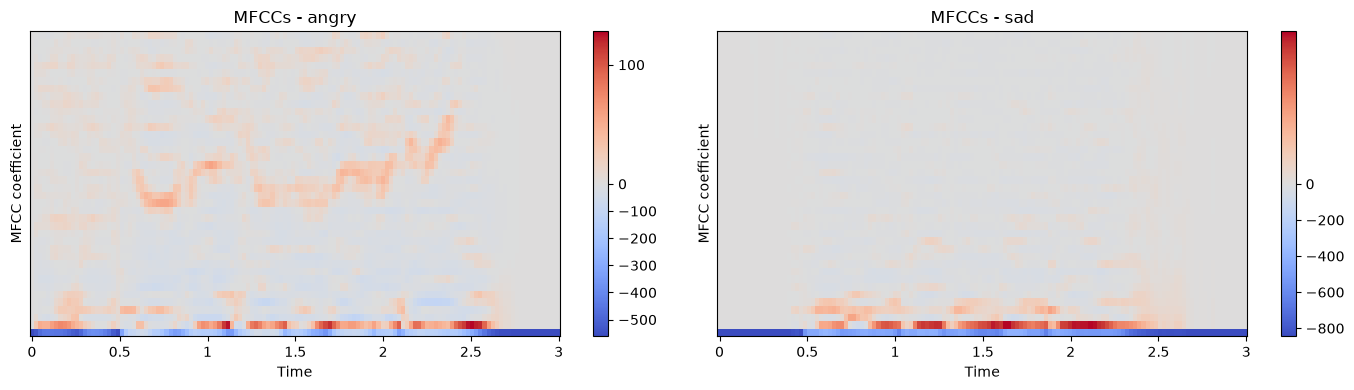

In [ ]:
# 5. Compare MFCCs: angry vs sad (same actor, same sentence, same intensity)
actor_id = 1
pair = {}
for emo in ["angry", "sad"]:
    row = df[(df.actor == actor_id) & (df.emotion == emo) &
             (df.intensity == "strong") & (df.statement == 1) & (df.repetition == 1)].iloc[0]
    pair[emo] = row["path"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (emo, path) in zip(axes, pair.items()):
    m = extract_mfcc(path)
    img = librosa.display.specshow(m, x_axis="time", sr=SR, hop_length=HOP_LENGTH, ax=ax)
    ax.set_title(f"MFCCs - {emo}")
    ax.set_ylabel("MFCC coefficient")
    fig.colorbar(img, ax=ax)
plt.tight_layout()
plt.show()
# Write 2-3 lines in your own words: how do the angry and sad MFCCs differ?

In [ ]:
# 6. Extract features for ALL clips (takes about 1-3 minutes)
features = []
failed = []

for i, path in enumerate(tqdm(df["path"], desc="Extracting MFCCs")):
    try:
        features.append(extract_mfcc(path))
    except Exception as e:
        failed.append((i, path, str(e)))
        features.append(np.zeros((N_MFCC, MAX_FRAMES), dtype=np.float32))   # keep row order intact

X = np.array(features, dtype=np.float32)
print("X shape:", X.shape)                             # expected (1440, 40, 130)
print("Failed files:", len(failed))                    # must be 0
if failed:
    print(failed[:3])

Extracting MFCCs: 100%|██████████| 1440/1440 [00:47<00:00, 30.40it/s]

X shape: (1440, 40, 130)
Failed files: 0


In [ ]:
# 7. Sanity checks BEFORE saving
assert X.shape == (len(df), N_MFCC, MAX_FRAMES), "Unexpected shape!"
assert not np.isnan(X).any(), "NaN values found!"
print("No NaNs. Value range:", X.min().round(1), "to", X.max().round(1))

padded_share = (X[:, :, -5:] == 0).all(axis=(1, 2)).mean()
print(f"Clips with zero-padding at the end: {padded_share:.1%}")

# Row-alignment check: re-extract 3 random clips and compare with the stored rows
rng = np.random.default_rng(42)
for i in rng.choice(len(df), size=3, replace=False):
    assert np.allclose(X[i], extract_mfcc(df.loc[i, "path"])), f"Row {i} does not match its file!"
print("Row alignment OK (row i of X matches row i of metadata).")

No NaNs. Value range: -1069.2 to 237.7
Clips with zero-padding at the end: 15.9%
Row alignment OK (row i of X matches row i of metadata).


In [ ]:
# 8. Save the features (never recompute them again)
np.save(BASE / "features" / "X_mfcc.npy", X)
size_mb = (BASE / "features" / "X_mfcc.npy").stat().st_size / 1e6
print(f"Saved features/X_mfcc.npy ({size_mb:.1f} MB)")

X_check = np.load(BASE / "features" / "X_mfcc.npy")
print("Reloaded shape:", X_check.shape, "| identical:", np.array_equal(X, X_check))

Saved features/X_mfcc.npy (30.0 MB)
Reloaded shape: (1440, 40, 130) | identical: True
